In [30]:
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
import pytz

### Required File Paths

In [31]:
results_folder = 'results/6Mar2024_03_51' # store the results in this folder

capture_file_path = '/home/ishani/LeoPNT/USRP_data/3_5/utctime_6Mar2024_03_51_14_freq_11_325G_bw_2.0M_ts_1709697074.3228533_inrx0.dat'
imu_file_path = '/home/ishani/LeoPNT/USRP_data/3_5/imu_utctime_2024_03_06_03_50_54.txt'
tle_path = '/home/ishani/LeoPNT/USRP_data/3_5/utctime_6Mar2024_03_50_54_starlink.tle'
phase_comp_mat_path = '/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/6Mar2024_03_51/phase_comp.mat'

### Get Candidate Locations for our GS 
```get_candidate_locs``` returns candidate clusters or groups, their centroids (serve as coarse location of GS candidates) 
and the satellites associates with each cluster

Initial number of candidate location clusters: 686
Possible: 67
Centroid of group  0 : [  42.80378728 -105.42937141]
Point that minimizes distance to each satellite trajectory : 42.672162145334184 -104.53498337365139
sats in group: ['STARLINK-1148', 'STARLINK-5715', 'STARLINK-30231', 'STARLINK-3668', 'STARLINK-30153', 'STARLINK-1873', 'STARLINK-5745', 'STARLINK-1845']
Centroid of group  1 : [ 42.67735873 -99.55865735]
Point that minimizes distance to each satellite trajectory : 42.25283425263062 -100.84090451400411
sats in group: ['STARLINK-1233', 'STARLINK-5513', 'STARLINK-2115', 'STARLINK-5715', 'STARLINK-4746', 'STARLINK-2046', 'STARLINK-5436', 'STARLINK-4770']
Centroid of group  2 : [ 39.89295244 -90.64634294]
Point that minimizes distance to each satellite trajectory : 39.95896108226503 -91.55873603356866
sats in group: ['STARLINK-1603', 'STARLINK-30507', 'STARLINK-5907', 'STARLINK-5074', 'STARLINK-5934', 'STARLINK-5934', 'STARLINK-3370', 'STARLINK-1846']
Centroid of group  3 : [ 

/home/ishani/LeoPNT/starlink_ofdm/Starloc/utils/satid_blind_identification.py:105: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


Centroid of group  4 : [ 47.1439054  -68.53132028]
Point that minimizes distance to each satellite trajectory : 47.5954446213728 -68.15210012968221
sats in group: ['STARLINK-1651', 'STARLINK-1138', 'STARLINK-1918', 'STARLINK-1983', 'STARLINK-2057', 'STARLINK-2019', 'STARLINK-3609', 'STARLINK-2056']
Centroid of group  5 : [  46.82453851 -108.35828829]
Point that minimizes distance to each satellite trajectory : 46.84432883226388 -106.16768426285873
sats in group: ['STARLINK-1893', 'STARLINK-1212', 'STARLINK-1545', 'STARLINK-1782', 'STARLINK-2114', 'STARLINK-1606', 'STARLINK-3368', 'STARLINK-4210']
Centroid of group  6 : [ 36.28016443 -76.17804628]
Point that minimizes distance to each satellite trajectory : 36.2478015282945 -76.45622445895778
sats in group: ['STARLINK-1785', 'STARLINK-5722', 'STARLINK-5950', 'STARLINK-30878', 'STARLINK-6116', 'STARLINK-2082', 'STARLINK-3100', 'STARLINK-4053']
Centroid of group  7 : [ 32.49284041 -94.77693101]
Point that minimizes distance to each satell

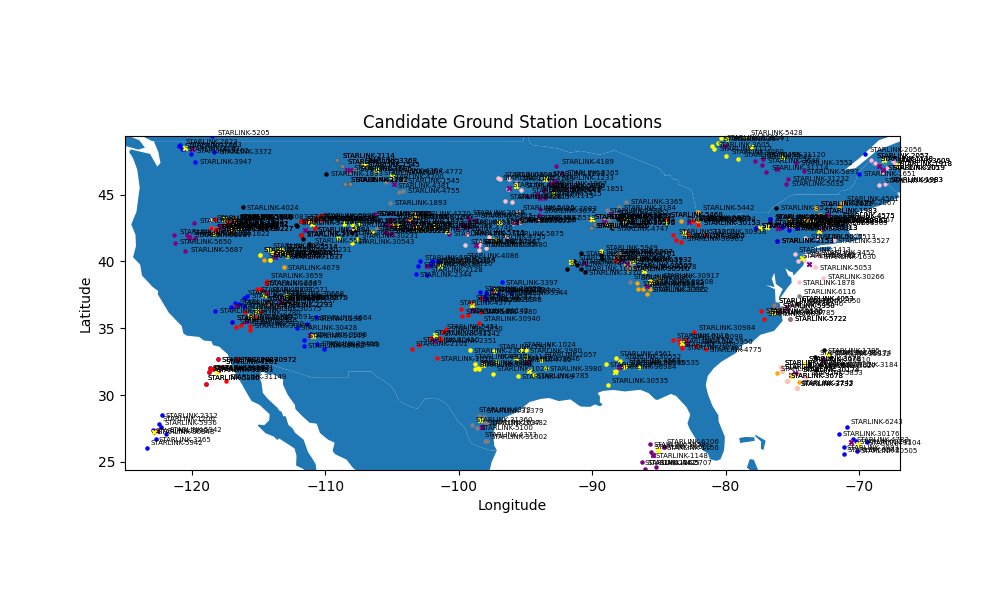

In [32]:
start_time = datetime.fromtimestamp(float(capture_file_path.split('_')[-2]), tz=pytz.utc)
phase_comp_mat = sio.loadmat(phase_comp_mat_path)
tracked_peaks = phase_comp_mat['dopp_track_dict'][0]
time_arr = []
for arr in tracked_peaks:
    time = np.median(np.real(arr[:,0]))
    time_arr.append(time)
## time_arr.append(580.0)
# sort time_arr
time_arr = sorted(time_arr)
%matplotlib widget
fig, ax = plt.subplots(1,1,figsize=(10,6))
# call get_candidate_locs
from utils.satid_blind_identification import get_candidate_locs
search_radius = 180 # in km
gs_groups, coarse_gs, sat_groups = get_candidate_locs(start_time, time_arr, tle_path, search_dist_bound=search_radius, fig_pointer=(fig, ax))
# plot the ground truth location
# get gt location from imu file
from utils.imu_data import IMUData
imu_data = IMUData(imu_file_path)
lat_lon_alt = imu_data.get_latlonalt()
# average out the lat lon alt
lat_lon_alt_mean = np.mean(lat_lon_alt, axis=0)
ax.scatter(lat_lon_alt_mean[1], lat_lon_alt_mean[0], c='red', marker='*',s=15)
# ax.scatter(-88.20952606201173, 40.07216262817384, c='red', marker='*',s=15)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Candidate Ground Station Locations')
plt.show()

### Narrowing down to a single candidate GS location
- The idea is to compare the observed phase difference at our receiver/GS with the simulated phase differences at the candidate GS locations. 
- The best match results in a single candidate GS. 
- The satellites that are observed by this GS at time in time array will be the SAT IDs.

##### 1. Simulating to get phase difference for all satellites observed by all ground stations at times in time_arr

In [35]:
## Simulating to get phase differences 
## =================================================
from sat_id import faster_doppler_sim
import pickle
import os

filesavepath = os.path.join(results_folder,'satdictlist_for_each_gs_.pkl') #TODO: change name/path if needed
load = True
# If kernel restarts or if satdictlist_for_each_gs.pkl is already, load it.
if load == True and os.path.exists(filesavepath):
    with open(filesavepath, 'rb') as f:
        satdictlist_for_each_gs = pickle.load(f)
else:
    # get satellite dopp dict for sats associated with each gs
    capture_start_timestamp = float(capture_file_path.split('_')[-2])
    print("start time: ", datetime.fromtimestamp(capture_start_timestamp, tz=pytz.utc))
    satdictlist_for_each_gs = [{} for i in range(len(coarse_gs))]

    #for each satellite at >75 degree min elevation wrt candidate gs, get the dopp, az, alt, range for about 10 secs around time in time_arr
    for gs_idx,cgs in enumerate(coarse_gs):
        for time in time_arr:
            # cgs = wgs84.latlon(cgs[0], cgs[1])
            # get sat dopp dict 
            date = '_'
            tle_path = tle_path
            fc = 11.325e9
            t_start = capture_start_timestamp + time - 5
            t_stop = capture_start_timestamp + time + 5
            t_step = 1
            gs = cgs
            # get sat dopp dict for this gs 
            sat_dopp_dict, _ = faster_doppler_sim(date, tle_path, fc, t_start, t_stop, t_step, gs, min_ele=75)
            satdictlist_for_each_gs[gs_idx][time] = sat_dopp_dict

    with open(filesavepath, 'wb') as f:
        pickle.dump(satdictlist_for_each_gs, f)

start time:  2024-03-06 03:51:14.322853+00:00
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  3
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  1
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  1
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  1
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  2
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  1
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  3
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  2
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  2
number of Starlink satellites loaded 5539
Duration in secs:  10

KeyboardInterrupt: 

###### 

##### 2. From the simulated alt, az, etc. get the phase differences and the parameters fro each phase difference line (slope and intercept)

In [36]:
# get phase diff params or all sats in each group
from utils.satid_blind_identification import get_phase_diff_params_allsatsingroups
# orientation_dict = {'alpha':0,'beta':1.5,'gamma':1.6}
print(orientation_dict)
phasediffdict_for_each_gs, phase_diff_param = get_phase_diff_params_allsatsingroups(coarse_gs, satdictlist_for_each_gs, time_arr, orientation_dict=orientation_dict)

{'alpha': 0, 'beta': 1.5, 'gamma': 1.6}
GS 0 Time 43.5610005
GS [  42.80378728 -105.42937141] Time 43.5610005 Sat: STARLINK-1148
GS [  42.80378728 -105.42937141] Time 43.5610005 Sat: STARLINK-5513
GS [  42.80378728 -105.42937141] Time 43.5610005 Sat: STARLINK-30266
GS 0 Time 109.79850049999999
GS [  42.80378728 -105.42937141] Time 109.79850049999999 Sat: STARLINK-5715
GS 0 Time 139.8040005
GS [  42.80378728 -105.42937141] Time 139.8040005 Sat: STARLINK-30231
GS 0 Time 179.6305005
GS [  42.80378728 -105.42937141] Time 179.6305005 Sat: STARLINK-3668
GS 0 Time 440.6010005
GS [  42.80378728 -105.42937141] Time 440.6010005 Sat: STARLINK-30153
GS [  42.80378728 -105.42937141] Time 440.6010005 Sat: STARLINK-1873
GS 0 Time 468.1670005
GS [  42.80378728 -105.42937141] Time 468.1670005 Sat: STARLINK-1873
GS 0 Time 730.7090005
GS [  42.80378728 -105.42937141] Time 730.7090005 Sat: STARLINK-4354
GS [  42.80378728 -105.42937141] Time 730.7090005 Sat: STARLINK-5745
GS [  42.80378728 -105.42937141] T

##### 3. Find the GS where the simulated phase difference parameters minimize the distance to the observed phase difference parameters

In [37]:
# find gs where the parameters minimize the difference with the observed phase diff
from utils.satid_blind_identification import find_best_coarse_gs
from utils.satid_blind_identification import get_observed_phase_diff_params
observed_phase_diff_params = get_observed_phase_diff_params(phase_comp_mat_path)
best_coarse_gs_candidate, best_candidate_idx, min_param_diff_pertime_each_gs, min_param_diff_sat_pertime_each_gs = find_best_coarse_gs(
                                                                                                coarse_gs, 
                                                                                                time_arr,
                                                                                                satdictlist_for_each_gs, 
                                                                                                phase_diff_param, 
                                                                                                observed_phase_diff_params)

No satellite found for GS: [ 47.1439054  -68.53132028]  at Time: 179.6305005
No satellite found for GS: [ 32.49284041 -94.77693101]  at Time: 179.6305005
No satellite found for GS: [ 32.49284041 -94.77693101]  at Time: 730.7090005
No satellite found for GS: [  34.47206274 -111.14913409]  at Time: 468.1670005
No satellite found for GS: [  34.47206274 -111.14913409]  at Time: 770.6580005
No satellite found for GS: [  45.76913825 -104.81114127]  at Time: 109.79850049999999
No satellite found for GS: [ 39.82322565 -73.75136545]  at Time: 109.79850049999999
No satellite found for GS: [  32.00952302 -118.13284315]  at Time: 139.8040005
No satellite found for GS: [ 43.55185051 -88.60608878]  at Time: 109.79850049999999
No satellite found for GS: [ 39.82212492 -87.42131857]  at Time: 770.6580005
No satellite found for GS: [ 42.23577442 -83.03046061]  at Time: 770.6580005
No satellite found for GS: [  31.88904303 -118.06252982]  at Time: 139.8040005
Best GS: [ 40.13675799 -87.77535972] Min Para

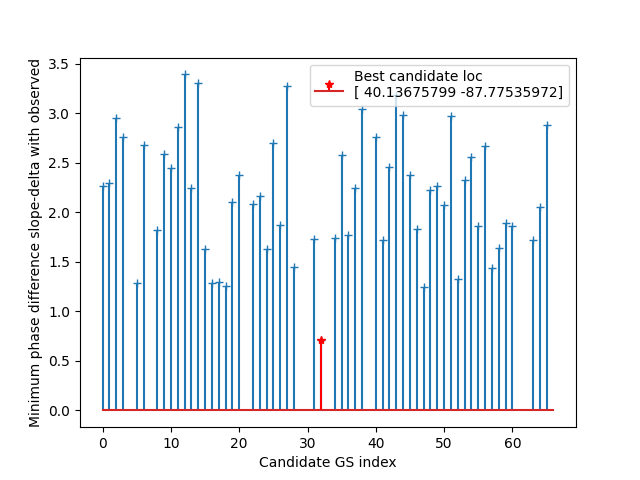

32

In [38]:
plt.figure()
plt.stem(range(len(coarse_gs)), np.sum(min_param_diff_pertime_each_gs, axis=1), markerfmt='+')
plt.stem(best_candidate_idx, np.sum(min_param_diff_pertime_each_gs, axis=1)[best_candidate_idx],markerfmt='*', linefmt='r', label='Best candidate loc\n'+str(best_coarse_gs_candidate))
plt.xlabel('Candidate GS index')
plt.ylabel('Minimum phase difference slope-delta with observed')
plt.legend()
plt.show()
best_candidate_idx

### Save data needed for localization

In [39]:
save_dict = {}
save_dict['real_gs'] = lat_lon_alt_mean
save_dict['centroid_gs'] = best_coarse_gs_candidate
save_dict['search_radius'] = search_radius
# get farthest gs in the candidate gs_group

from utils.helper import get_distkm_latlon_coordinates

loc1 = lat_lon_alt_mean[:2]
loc2 = gs_groups[best_candidate_idx]
dists = get_distkm_latlon_coordinates(loc1, loc2)
farthest_gs_idx = np.argmax(dists)
farthest_gs = gs_groups[best_candidate_idx][farthest_gs_idx]
d1 = search_radius - get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (lat_lon_alt_mean[0], farthest_gs[1]))
d2 = search_radius + get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (lat_lon_alt_mean[0], farthest_gs[1]))
d3 = search_radius + get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (farthest_gs[0], lat_lon_alt_mean[1]))
d4 = search_radius - get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (farthest_gs[0], lat_lon_alt_mean[1]))

save_dict['farthest_gs'] = farthest_gs
save_dict['d1'] = d1 # distance to left/west boundary
save_dict['d2'] = d2 # distance to right/east boundary
save_dict['d3'] = d3 # distance to top/north boundary
save_dict['d4'] = d4 # distance to bottom/south boundary
print('d1: ', d1, 'd2: ', d2, 'd3: ', d3, 'd4: ', d4)
sio.savemat(os.path.join(results_folder,'coarsegs_search.mat'), save_dict) #TODO: change name/path if needed

d1:  [44.05226767] d2:  [315.94773233] d3:  [189.5644488] d4:  [170.4355512]


### Save output_doppler_coarsegs.mat generated with the coarse_gs location

In [41]:
from sat_id import faster_doppler_sim
import os 

date = results_folder.split('/')[-1]
print(date)
if not os.path.exists(os.path.join(results_folder, "info.mat")):
    print("Run Starloc.ipynb first to get info.mat")
fc = 11.325e9
sim_start_time = float(capture_file_path.split('_')[-2])
t_end = sio.loadmat(os.path.join(results_folder, "info.mat"))['t_end'][0][0]
lat_gt, lon_gt = best_coarse_gs_candidate
sim_end_time = sim_start_time+t_end
# sat_dopp_dict, t_list = doppler_sim(date, date+'/Starlink.tle', fc, sim_start_time, sim_end_time, 1)
sat_dopp_dict, t_list = faster_doppler_sim(date, tle_path, fc, sim_start_time, sim_end_time, 1, ground_station=(lat_gt, lon_gt))
output_doppler_file = os.path.join(results_folder,"output_doppler_coarsegs.mat")
output = {}
sio.savemat(output_doppler_file, {'sat_dopp_dict': sat_dopp_dict, 't_list': t_list})

6Mar2024_03_51
number of Starlink satellites loaded 5539
Duration in secs:  879.1562879085541
Number of visible satellites:  49
